In [1]:
!pip install -q ultralytics roboflow pyyaml seaborn

In [2]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable a GPU from Runtime settings.")

PyTorch: 2.14.1+cu130
Ultralytics: 8.4.211
GPU available: True
GPU name: Tesla T4


In [3]:
from google.colab import userdata
from roboflow import Roboflow

api_key = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)

project = rf.workspace(
    "detection-benchmark"
).project(
    "gtsdb---german-traffic-sign-detection-benchmark-yjudr"
)

dataset = project.version(1).download("yolov8")

DATASET_DIR = dataset.location
print("Dataset path:", DATASET_DIR)

loading Roboflow workspace...
loading Roboflow project...
Dataset path: /content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1


In [4]:
from pathlib import Path
import yaml

DATASET_DIR = Path(DATASET_DIR)
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATA_YAML.exists(), (
    f"Could not find data.yaml at {DATA_YAML}"
)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print("Dataset directory:", DATASET_DIR)
print("\nDataset configuration:")
print(yaml.safe_dump(data_config, sort_keys=False))

print("\nDataset files:")
for path in list(DATASET_DIR.iterdir()):
    print(path.name)

Dataset directory: /content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1

Dataset configuration:
names:
- Bicycles crossing
- Curve to the left
- Curve to the right
- General caution
- NO ENTRY
- PEDESTRIAN CROSSING
- Road works
- SCHOOL CROSSING
- SNOW
- STOP
- bend
- give way
- priority road
- road narrows
- slippery road
- speed limit 20
- traffic signal
- uneven road
nc: 18
roboflow:
  license: CC BY 4.0
  project: gtsdb---german-traffic-sign-detection-benchmark-yjudr
  url: https://universe.roboflow.com/detection-benchmark/gtsdb---german-traffic-sign-detection-benchmark-yjudr/dataset/1
  version: 1
  workspace: detection-benchmark
test: ../test/images
train: ../train/images
val: ../valid/images


Dataset files:
train
valid
data.yaml
test
README.dataset.txt
README.roboflow.txt


Number of classes: 18
Classes: ['Bicycles crossing', 'Curve to the left', 'Curve to the right', 'General caution', 'NO ENTRY', 'PEDESTRIAN CROSSING', 'Road works', 'SCHOOL CROSSING', 'SNOW', 'STOP', 'bend', 'give way', 'priority road', 'road narrows', 'slippery road', 'speed limit 20', 'traffic signal', 'uneven road']
/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1/train/images
this path directly lead to file image
Training images found: 606


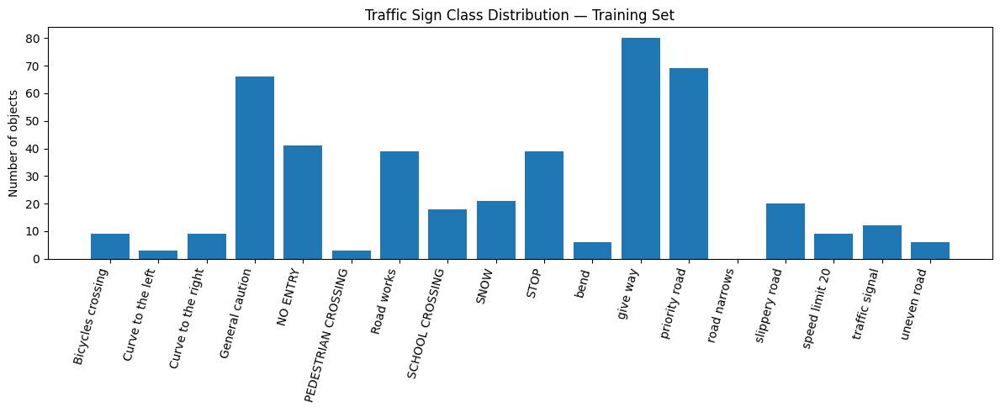

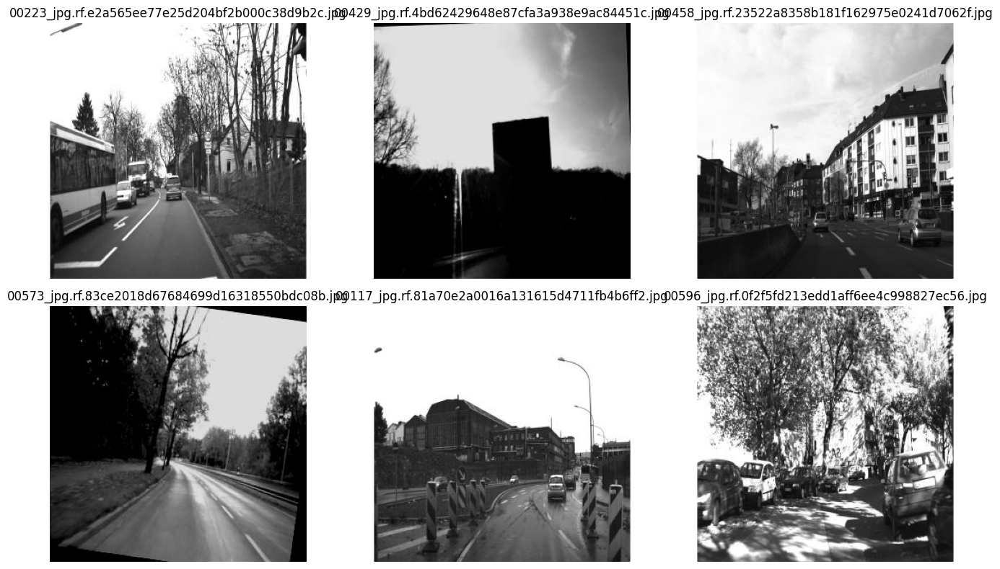

In [5]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import random

names = data_config["names"]
if isinstance(names, list):
    class_names = names
else:
    class_names = [
        names[i] for i in sorted(names.keys(), key=int)
    ]

print("Number of classes:", len(class_names))
print("Classes:", class_names)

train_path = Path(data_config["train"])
# print(train_path)
if not train_path.is_absolute():
   train_path = DATASET_DIR / "train/images"
    # train_path = DATASET_DIR / train_path
   print(train_path)

# Find training images, supporting common folder layouts.
if train_path.is_dir() and train_path.name == "images":
    train_images_dir = train_path
    print("this path directly lead to file image")
elif (train_path / "images").is_dir():
    train_images_dir = train_path / "images"
    print("this path has file image")

else:
    train_images_dir = train_path
    print("this path has the images")


image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_paths = [
    p for p in train_images_dir.rglob("*")
    if p.suffix.lower() in image_extensions
]

print("Training images found:", len(image_paths))
assert image_paths, "No training images found. Check data.yaml paths."

# Count class instances in YOLO label files.
label_counts = Counter()
labels_dir = DATASET_DIR / "train" / "labels"

if not labels_dir.exists():
    labels_dir = DATASET_DIR / "labels" / "train"

for image_path in image_paths:
    label_path = (
        image_path.parent.parent / "labels" / f"{image_path.stem}.txt"
    )
    if not label_path.exists():
        label_path = labels_dir / f"{image_path.stem}.txt"

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                label_counts[int(float(parts[0]))] += 1

plt.figure(figsize=(12, 5))
plt.bar(
    [class_names[i] for i in range(len(class_names))],
    [label_counts[i] for i in range(len(class_names))]
)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of objects")
plt.title("Traffic Sign Class Distribution — Training Set")
plt.tight_layout()
plt.show()

# Show random images for visual inspection.
sample_paths = random.sample(
    image_paths, min(6, len(image_paths))
)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, path in zip(axes.flat, sample_paths):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(path.name)
    ax.axis("off")

for ax in axes.flat[len(sample_paths):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

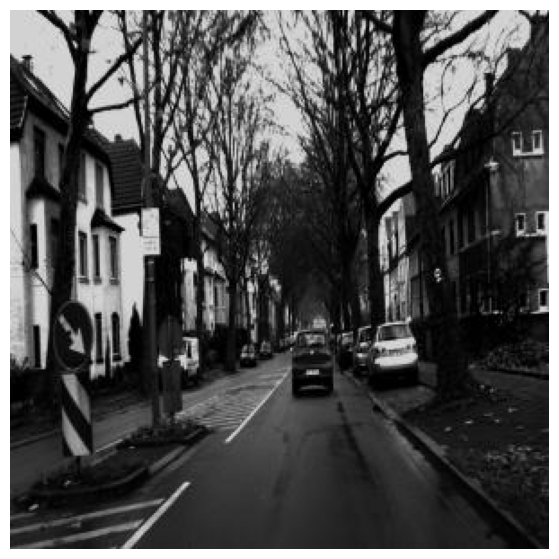

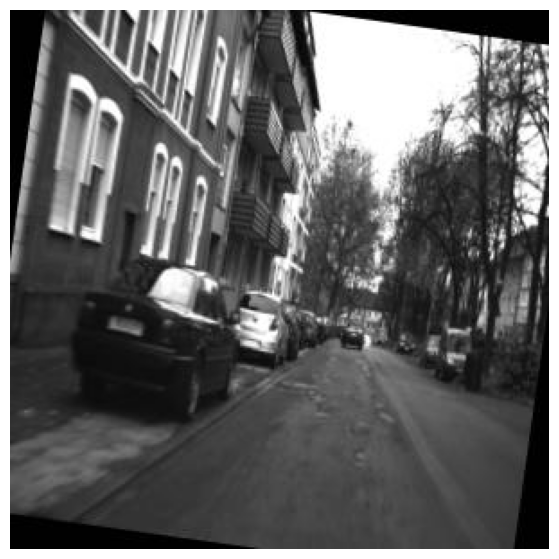

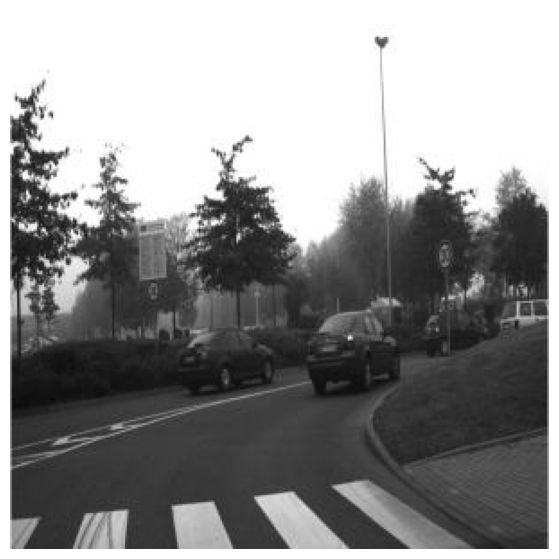

In [6]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import random

def get_label_path(image_path):
    image_path = Path(image_path)

    # Standard YOLO folder convention:
    # .../images/train/example.jpg -> .../labels/train/example.txt
    parts = list(image_path.parts)
    for i, part in enumerate(parts):
        if part == "images":
            parts[i] = "labels"
            return Path(*parts).with_suffix(".txt")

    return None


def show_yolo_labels(image_path):
    image = cv2.imread(str(image_path))
    assert image is not None, f"Cannot read {image_path}"

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]
    label_path = get_label_path(image_path)

    if label_path is not None and label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(
                image, (x1, y1), (x2, y2), (0, 255, 0), 2
            )
            class_id = int(cls)
            name = (
                class_names[class_id]
                if class_id < len(class_names)
                else str(class_id)
            )
            cv2.putText(
                image, name, (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
            )

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

for path in random.sample(image_paths, min(3, len(image_paths))):
    show_yolo_labels(path)

In [7]:
from collections import Counter
from pathlib import Path
import pandas as pd

# Resolve class names
names = data_config["names"]

if isinstance(names, list):
    class_names = names
else:
    class_names = [
        names[i] for i in sorted(names.keys(), key=int)
    ]

num_classes = len(class_names)

# Counters
class_counts = Counter()
missing_labels = []
empty_labels = []
invalid_labels = []
valid_labels = 0

for image_path in image_paths:

    label_path = get_label_path(image_path)

    if label_path is None or not label_path.exists():
        missing_labels.append(image_path.name)
        continue

    lines = label_path.read_text().strip().splitlines()

    if not lines:
        empty_labels.append(image_path.name)
        continue

    valid_file = True

    for line in lines:
        parts = line.split()

        if len(parts) != 5:
            valid_file = False
            invalid_labels.append((image_path.name, line))
            continue

        try:
            cls, xc, yc, bw, bh = map(float, parts)
        except ValueError:
            valid_file = False
            invalid_labels.append((image_path.name, line))
            continue

        class_id = int(cls)

        if (
            cls != class_id
            or not (0 <= class_id < num_classes)
            or not (0 <= xc <= 1)
            or not (0 <= yc <= 1)
            or not (0 < bw <= 1)
            or not (0 < bh <= 1)
            or xc - bw / 2 < 0
            or yc - bh / 2 < 0
            or xc + bw / 2 > 1
            or yc + bh / 2 > 1
        ):
            valid_file = False
            invalid_labels.append((image_path.name, line))
            continue

        class_counts[class_id] += 1

    if valid_file:
        valid_labels += 1

# Build report
report = pd.DataFrame({
    "Class ID": range(num_classes),
    "Class Name": class_names,
    "Object Count": [
        class_counts[i] for i in range(num_classes)
    ]
})

print("Number of classes:", num_classes)
print("Training images:", len(image_paths))
print("Valid label files:", valid_labels)
print("Missing label files:", len(missing_labels))
print("Empty label files:", len(empty_labels))
print("Invalid annotations:", len(invalid_labels))

display(report)

print("\nClasses with zero instances:")
display(report[report["Object Count"] == 0])

Number of classes: 18
Training images: 606
Valid label files: 332
Missing label files: 0
Empty label files: 274
Invalid annotations: 0


,Class ID,Class Name,Object Count
0,0,Bicycles crossing,9
1,1,Curve to the left,3
2,2,Curve to the right,9
3,3,General caution,66
4,4,NO ENTRY,41
5,5,PEDESTRIAN CROSSING,3
6,6,Road works,39
7,7,SCHOOL CROSSING,18
8,8,SNOW,21
9,9,STOP,39



Classes with zero instances:


,Class ID,Class Name,Object Count
13,13,road narrows,0


Empty-label images: 274


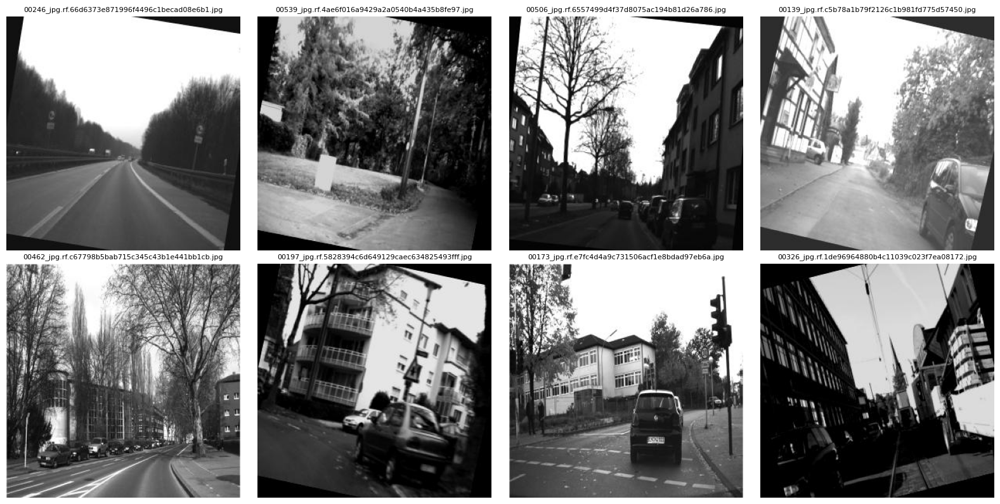

In [8]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# Find images with empty annotation files
empty_image_paths = []

for image_path in image_paths:
    label_path = get_label_path(image_path)

    if label_path is not None and label_path.exists():
        if not label_path.read_text().strip():
            empty_image_paths.append(image_path)

print("Empty-label images:", len(empty_image_paths))

# Display random empty-label samples
samples = random.sample(
    empty_image_paths,
    min(16, len(empty_image_paths))
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, path in zip(axes.flat, samples):
    image = Image.open(path).convert("RGB")

    ax.imshow(image)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from pathlib import Path
from collections import Counter
import pandas as pd

def count_split_classes(split_name):

    split_path = Path(data_config[split_name])

    if not split_path.is_absolute():
        split_path = DATASET_DIR / f"{split_name}" / "images"
        print(split_path)
    # # # Normalize the path and resolve '..'
    # # split_path = split_path.resolve()

    # print(f"{split_name} path: {split_path}")

    if split_path.name == "images":
        images_dir = split_path
    elif (split_path / "images").exists():
        images_dir = split_path / "images"
    else:
        images_dir = split_path

    labels_dir = (
        images_dir.parent / "labels"
    )

    counts = Counter()

    for image_path in images_dir.rglob("*"):

        if image_path.suffix.lower() not in image_extensions:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        for line in label_path.read_text().splitlines():

            parts = line.split()

            if len(parts) == 5:
                class_id = int(float(parts[0]))
                counts[class_id] += 1

    return counts


split_results = {}

for split in ["train", "val", "test"]:

    if split not in data_config:
        continue

    counts = count_split_classes(split)

    split_results[split] = counts

comparison = pd.DataFrame({
    "Class": class_names,
    "Train": [
        split_results.get("train", {}).get(i, 0)
        for i in range(len(class_names))
    ],
    "Validation": [
        split_results.get("val", {}).get(i, 0)
        for i in range(len(class_names))
    ],
    "Test": [
        split_results.get("test", {}).get(i, 0)
        for i in range(len(class_names))
    ]
})

display(comparison)

/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1/train/images
/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1/val/images
/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1/test/images


,Class,Train,Validation,Test
0,Bicycles crossing,9,0,1
1,Curve to the left,3,0,1
2,Curve to the right,9,0,0
3,General caution,66,0,1
4,NO ENTRY,41,0,1
5,PEDESTRIAN CROSSING,3,0,0
6,Road works,39,0,2
7,SCHOOL CROSSING,18,0,0
8,SNOW,21,0,0
9,STOP,39,0,1


In [10]:
from pathlib import Path

print("DATASET DIRECTORY:")
print(DATASET_DIR)

print("\nDATA CONFIGURATION:")
for key, value in data_config.items():
    print(f"{key}: {value}")

print("\nDATASET FOLDER STRUCTURE:")

for folder in DATASET_DIR.iterdir():

    if folder.is_dir():

        print(f"\nFolder: {folder.name}")

        for subfolder in folder.iterdir():

            if subfolder.is_dir():

                print(
                    f"  {subfolder.name}: "
                    f"{len(list(subfolder.iterdir()))} files"
                )

DATASET DIRECTORY:
/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1

DATA CONFIGURATION:
names: ['Bicycles crossing', 'Curve to the left', 'Curve to the right', 'General caution', 'NO ENTRY', 'PEDESTRIAN CROSSING', 'Road works', 'SCHOOL CROSSING', 'SNOW', 'STOP', 'bend', 'give way', 'priority road', 'road narrows', 'slippery road', 'speed limit 20', 'traffic signal', 'uneven road']
nc: 18
roboflow: {'license': 'CC BY 4.0', 'project': 'gtsdb---german-traffic-sign-detection-benchmark-yjudr', 'url': 'https://universe.roboflow.com/detection-benchmark/gtsdb---german-traffic-sign-detection-benchmark-yjudr/dataset/1', 'version': 1, 'workspace': 'detection-benchmark'}
test: ../test/images
train: ../train/images
val: ../valid/images

DATASET FOLDER STRUCTURE:

Folder: train
  labels: 606 files
  images: 606 files

Folder: valid
  labels: 58 files
  images: 58 files

Folder: test
  labels: 26 files
  images: 26 files


In [11]:
from pathlib import Path
from collections import Counter
import pandas as pd

# Actual dataset directories
splits = {
    "Train": DATASET_DIR / "train",
    "Validation": DATASET_DIR / "valid",
    "Test": DATASET_DIR / "test"
}

split_counts = {}
split_stats = {}

for split_name, split_dir in splits.items():

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    counts = Counter()

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in image_extensions
    ]

    missing = 0
    empty = 0
    annotated = 0

    for image_path in images:

        label_path = labels_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing += 1
            continue

        lines = label_path.read_text().splitlines()

        if not any(line.strip() for line in lines):
            empty += 1
            continue

        annotated += 1

        for line in lines:

            parts = line.split()

            if len(parts) == 5:
                class_id = int(float(parts[0]))
                counts[class_id] += 1

    split_counts[split_name] = counts

    split_stats[split_name] = {
        "Images": len(images),
        "Annotated Images": annotated,
        "Empty Labels": empty,
        "Missing Labels": missing,
        "Objects": sum(counts.values())
    }

# Class comparison
comparison = pd.DataFrame({
    "Class": class_names,
    "Train": [
        split_counts["Train"].get(i, 0)
        for i in range(len(class_names))
    ],
    "Validation": [
        split_counts["Validation"].get(i, 0)
        for i in range(len(class_names))
    ],
    "Test": [
        split_counts["Test"].get(i, 0)
        for i in range(len(class_names))
    ]
})

print("SPLIT STATISTICS")
display(pd.DataFrame(split_stats).T)

print("\nCLASS DISTRIBUTION")
display(comparison)

print("\nClasses missing from training:")
display(
    comparison[comparison["Train"] == 0]
)

SPLIT STATISTICS


,Images,Annotated Images,Empty Labels,Missing Labels,Objects
Train,606,332,274,0,450
Validation,58,27,31,0,36
Test,26,12,14,0,14



CLASS DISTRIBUTION


,Class,Train,Validation,Test
0,Bicycles crossing,9,0,1
1,Curve to the left,3,0,1
2,Curve to the right,9,1,0
3,General caution,66,1,1
4,NO ENTRY,41,4,1
5,PEDESTRIAN CROSSING,3,1,0
6,Road works,39,2,2
7,SCHOOL CROSSING,18,0,0
8,SNOW,21,7,0
9,STOP,39,2,1



Classes missing from training:


,Class,Train,Validation,Test
13,road narrows,0,0,1


Train: 274 empty images


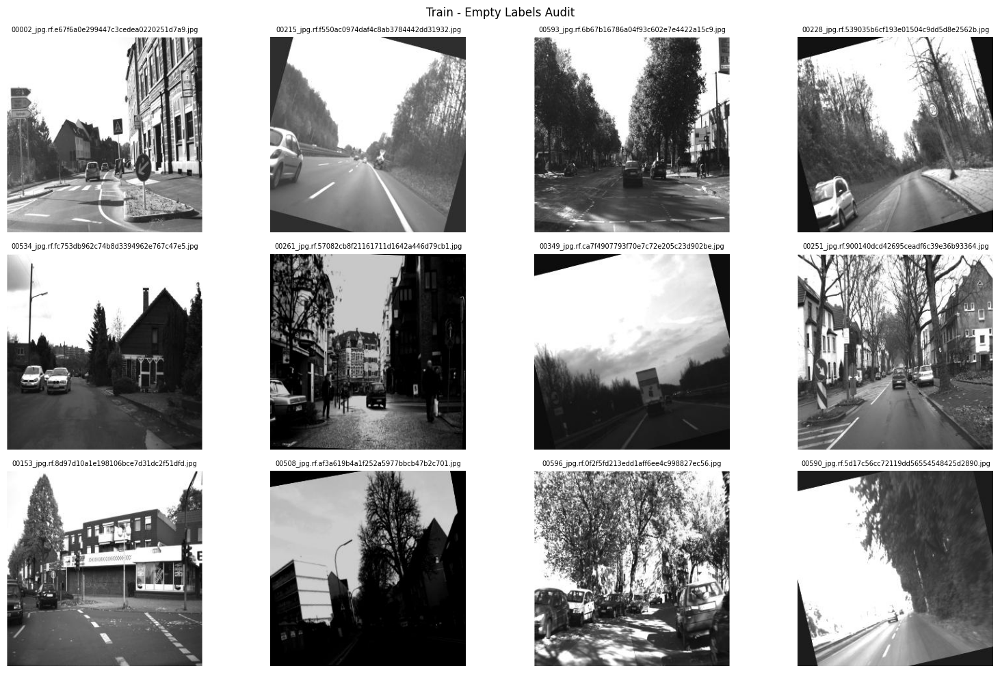

Validation: 31 empty images


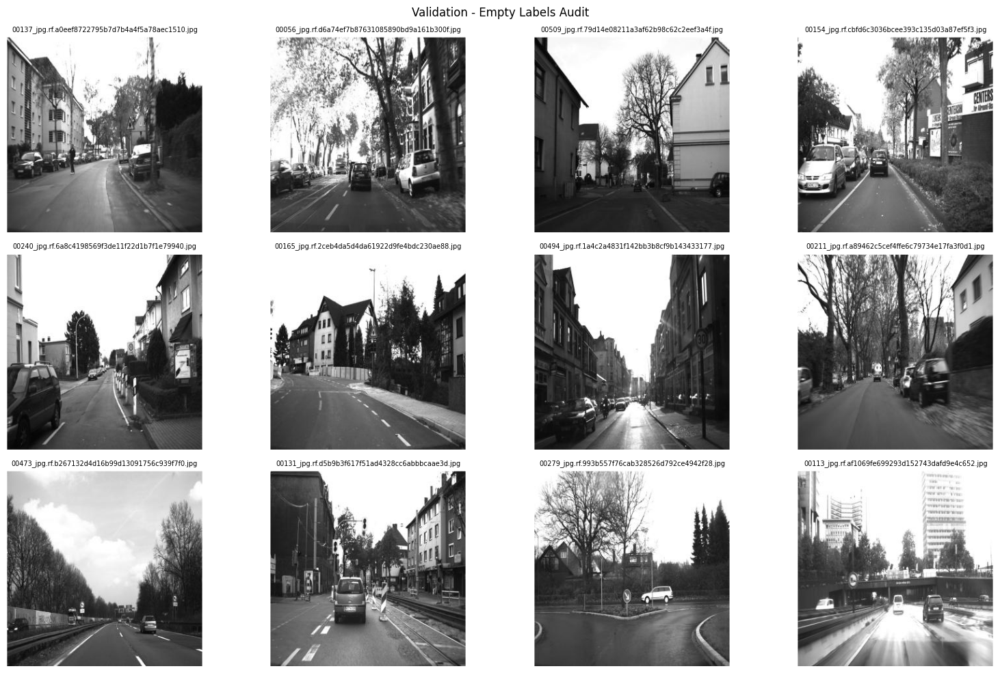

Test: 14 empty images


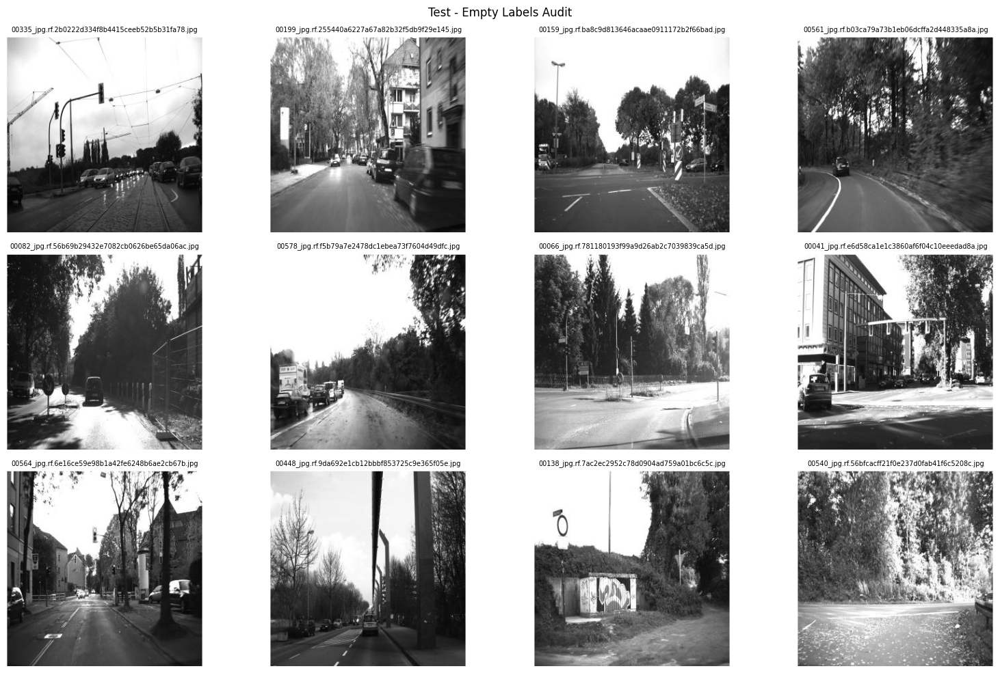

In [12]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

random.seed(42)

for split_name, split_dir in splits.items():

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    empty_images = []

    for image_path in images_dir.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"

        if label_path.exists():

            if not label_path.read_text().strip():
                empty_images.append(image_path)

    sample_size = min(12, len(empty_images))

    samples = random.sample(
        empty_images,
        sample_size
    )

    print(
        f"{split_name}: "
        f"{len(empty_images)} empty images"
    )

    fig, axes = plt.subplots(
        3, 4,
        figsize=(16, 10)
    )

    axes = axes.flatten()

    for ax, image_path in zip(axes, samples):

        img = Image.open(image_path).convert("RGB")

        ax.imshow(img)
        ax.set_title(image_path.name, fontsize=7)
        ax.axis("off")

    for ax in axes[sample_size:]:
        ax.axis("off")

    plt.suptitle(
        f"{split_name} - Empty Labels Audit"
    )

    plt.tight_layout()
    plt.show()

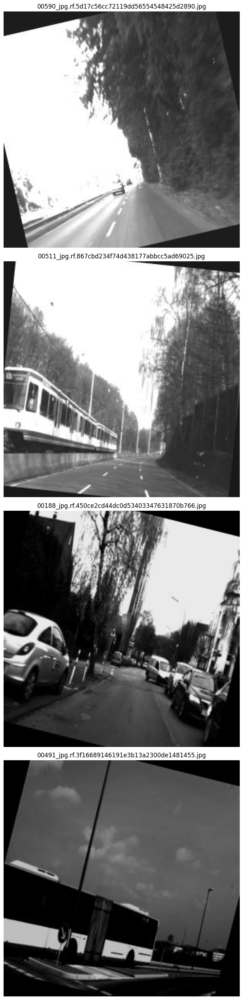

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import random

def show_empty_samples(split_name, n=4):

    split_dir = splits[split_name]
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    empty_images = []

    for img_path in images_dir.iterdir():

        if img_path.suffix.lower() not in image_extensions:
            continue

        label_path = labels_dir / f"{img_path.stem}.txt"

        if label_path.exists() and not label_path.read_text().strip():
            empty_images.append(img_path)

    samples = random.sample(
        empty_images,
        min(n, len(empty_images))
    )

    fig, axes = plt.subplots(
        len(samples), 1,
        figsize=(14, 7 * len(samples))
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, path in zip(axes, samples):

        img = Image.open(path).convert("RGB")

        ax.imshow(img)
        ax.set_title(path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_empty_samples("Train", 4)


Image: 00505_jpg.rf.acf6f21342245a38adc3b118c3308d00.jpg
Class: priority road | Box: (48, 164, 59, 181)


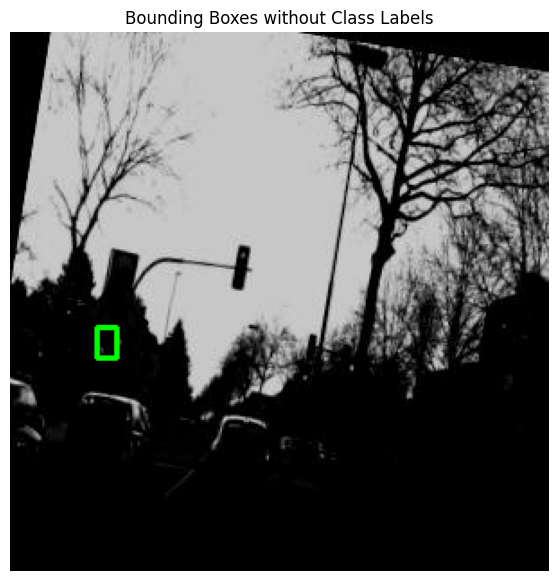


Image: 00238_jpg.rf.129d401cace8052b4b821cf3f121d630.jpg
Class: General caution | Box: (185, 149, 194, 162)


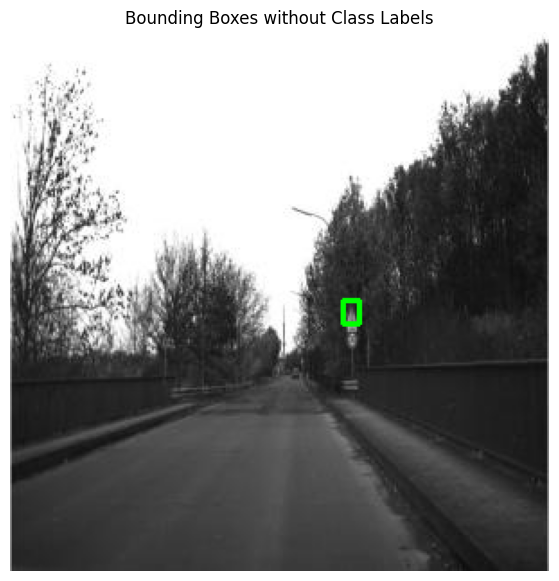


Image: 00256_jpg.rf.e21d99246b0551d8c003aad051cc1f6f.jpg
Class: General caution | Box: (244, 15, 272, 57)


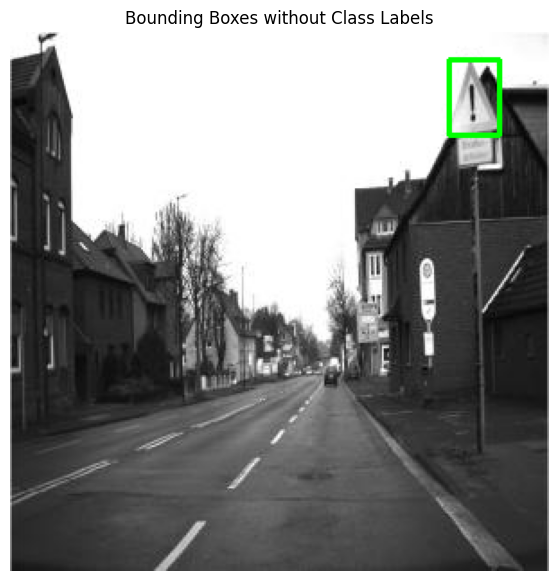

In [14]:
import cv2
import matplotlib.pyplot as plt
import random

def show_boxes_only(image_path):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    label_path = get_label_path(image_path)

    print(f"\nImage: {image_path.name}")

    if label_path is None or not label_path.exists():
        print("No label file found.")
        return

    for line in label_path.read_text().splitlines():

        parts = line.split()

        if len(parts) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts)

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)

        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        # Draw rectangle without class text
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        print(
            f"Class: {class_names[int(cls)]} | "
            f"Box: ({x1}, {y1}, {x2}, {y2})"
        )

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title("Bounding Boxes without Class Labels")
    plt.axis("off")
    plt.show()


# Select images that contain annotations
annotated_images = []

for path in image_paths:
    label_path = get_label_path(path)

    if label_path and label_path.exists():
        if label_path.read_text().strip():
            annotated_images.append(path)

for path in random.sample(
    annotated_images,
    min(3, len(annotated_images))
):
    show_boxes_only(path)

preprocess before training

In [15]:
# ===== Inventory of images / labels / boxes + resolution check =====
import random
import numpy as np
import pandas as pd
from collections import Counter
from pathlib import Path
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
ORIG_SPLITS = {
    "train": Path(DATASET_DIR) / "train",
    "val":   Path(DATASET_DIR) / "valid",
    "test":  Path(DATASET_DIR) / "test",
}

rows, boxes = [], []
for split, d in ORIG_SPLITS.items():
    for img in sorted((d / "images").iterdir()):
        if img.suffix.lower() not in IMG_EXT:
            continue
        lbl = d / "labels" / f"{img.stem}.txt"
        with Image.open(img) as im:
            W, H = im.size
        objs = []
        if lbl.exists():
            for line in lbl.read_text().splitlines():
                p = line.split()
                if len(p) == 5:
                    c = int(float(p[0]))
                    xc, yc, bw, bh = map(float, p[1:])
                    objs.append((c, xc, yc, bw, bh))
                    boxes.append(dict(split=split, image=img.name, cls=c,
                                      w_px=bw * W, h_px=bh * H))
        rows.append(dict(split=split, image=img, W=W, H=H,
                         n_obj=len(objs), objs=objs))

inv = pd.DataFrame(rows)
box_df = pd.DataFrame(boxes)

print("Images per split:\n", inv.groupby("split").size().to_string())
print("\nImage sizes (W, H) -> number of images:\n",
      inv.groupby(["W", "H"]).size().to_string())

box_df["max_side"] = box_df[["w_px", "h_px"]].max(axis=1)
print("\nBox size in pixels:\n", box_df[["w_px", "h_px"]].describe().round(1).to_string())
for t in (8, 12, 16, 32):
    print(f"Boxes with max side < {t:>2}px: {(box_df.max_side < t).mean():.1%}")

Images per split:
 split
test      26
train    606
val       58

Image sizes (W, H) -> number of images:
 W    H  
300  300    690

Box size in pixels:
         w_px   h_px
count  500.0  500.0
mean    12.9   19.6
std      6.7    9.6
min      3.5    7.0
25%      8.0   13.0
50%     11.0   17.0
75%     16.1   25.1
max     39.0   55.0
Boxes with max side <  8px: 1.8%
Boxes with max side < 12px: 18.8%
Boxes with max side < 16px: 45.0%
Boxes with max side < 32px: 87.8%


In [16]:
# ===== Drop classes with no training data (road narrows) =====
DROP_CLASSES = {"road narrows"}

missing = DROP_CLASSES - set(class_names)
assert not missing, f"Class names not found in class_names: {missing}"

def final_name(n):
    return None if n in DROP_CLASSES else n

new_names = [n for n in class_names if final_name(n) is not None]
old2new = {i: new_names.index(n) for i, n in enumerate(class_names)
           if final_name(n) is not None}

def remap(objs):
    return [(old2new[c], *rest) for c, *rest in objs if c in old2new]

inv["objs_new"] = inv.objs.apply(remap)
# images that contain a dropped class -> excluded later (the sign would stay unlabelled)
inv["has_dropped"] = inv.objs.apply(lambda o: any(c not in old2new for c, *_ in o))

print("Classes before:", len(class_names), "| after:", len(new_names))
print("Dropped:", sorted(DROP_CLASSES))
print("Images containing a dropped class:", int(inv.has_dropped.sum()))
print(inv[inv.has_dropped][["split", "image"]]
      .assign(image=lambda d: d.image.map(lambda p: p.name)).to_string(index=False))

Classes before: 18 | after: 17
Dropped: ['road narrows']
Images containing a dropped class: 1
split                                             image
 test 00265_jpg.rf.70fe957119b71a34c5478596ed8cd5c0.jpg


In [17]:

# # ===== 3-Fold Multilabel Stratified Cross Validation =====

# !pip -q install iterative-stratification ultralytics

# from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
# from pathlib import Path
# import numpy as np
# import pandas as pd
# import yaml

# # 1. Collect Train + Validation images
# splits = ["train", "valid"]

# all_images = []

# for split in splits:
#     image_dir = Path(DATASET_DIR) / split / "images"

#     for img in sorted(image_dir.iterdir()):
#         if img.suffix.lower() in IMG_EXT:
#             all_images.append(img)

# # 2. Build a multi-label matrix
# class_names = [
#     'Bicycles crossing',
#     'Curve to the left',
#     'Curve to the right',
#     'General caution',
#     'NO ENTRY',
#     'PEDESTRIAN CROSSING',
#     'Road works',
#     'SCHOOL CROSSING',
#     'SNOW',
#     'STOP',
#     'bend',
#     'give way',
#     'priority road',
#     'road narrows',
#     'slippery road',
#     'speed limit 20',
#     'traffic signal',
#     'uneven road'
# ]

# NUM_CLASSES = len(class_names)

# Y = np.zeros((len(all_images), NUM_CLASSES), dtype=int)

# for i, img in enumerate(all_images):

#     label_path = (
#         img.parent.parent / "labels" / f"{img.stem}.txt"
#     )

#     if label_path.exists():

#         for line in label_path.read_text().splitlines():

#             p = line.split()

#             if len(p) == 5:
#                 cls = int(float(p[0]))

#                 if 0 <= cls < NUM_CLASSES:
#                     Y[i, cls] = 1

# print("Total images:", len(all_images))
# print("Label matrix shape:", Y.shape)

# # 3. Check number of images containing each class
# class_image_counts = Y.sum(axis=0)

# class_report = pd.DataFrame({
#     "Class": class_names,
#     "Images containing class": class_image_counts
# })

# print("\nClass presence per image:")
# display(class_report)

# # 4. Create 3 folds
# N_SPLITS = 3

# mskf = MultilabelStratifiedKFold(
#     n_splits=N_SPLITS,
#     shuffle=True,
#     random_state=42
# )

# FOLD_DIR = Path("/content/traffic_sign_folds")
# FOLD_DIR.mkdir(parents=True, exist_ok=True)

# folds = []

# for fold, (train_idx, val_idx) in enumerate(
#     mskf.split(np.zeros(len(Y)), Y), start=1
# ):

#     train_images = [all_images[i] for i in train_idx]
#     val_images = [all_images[i] for i in val_idx]

#     train_txt = FOLD_DIR / f"fold_{fold}_train.txt"
#     val_txt = FOLD_DIR / f"fold_{fold}_val.txt"

#     train_txt.write_text(
#         "\n".join(str(p.resolve()) for p in train_images)
#     )

#     val_txt.write_text(
#         "\n".join(str(p.resolve()) for p in val_images)
#     )

#     # Create YOLO dataset configuration
#     data_config = {
#         "train": str(train_txt),
#         "val": str(val_txt),
#         "nc": NUM_CLASSES,
#         "names": class_names
#     }

#     yaml_path = FOLD_DIR / f"fold_{fold}.yaml"

#     with open(yaml_path, "w") as f:
#         yaml.safe_dump(
#             data_config,
#             f,
#             sort_keys=False,
#             allow_unicode=True
#         )

#     folds.append({
#         "fold": fold,
#         "train_images": len(train_images),
#         "val_images": len(val_images),
#         "yaml": str(yaml_path)
#     })

# print("\nFOLD SUMMARY")
# display(pd.DataFrame(folds))

# # 5. Check class distribution in each fold
# for fold, (_, val_idx) in enumerate(
#     mskf.split(np.zeros(len(Y)), Y), start=1
# ):
#     print(f"\nFold {fold} validation distribution:")

#     counts = Y[val_idx].sum(axis=0)

#     print(pd.DataFrame({
#         "Class": class_names,
#         "Images": counts
#     }).to_string(index=False))






# ===== 3-Fold Multilabel Stratified Cross Validation =====

!pip -q install iterative-stratification ultralytics

from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import os
import shutil

# =====================================================
# 1. Define original classes and remove unwanted classes
# =====================================================

original_class_names = [
    'Bicycles crossing',
    'Curve to the left',
    'Curve to the right',
    'General caution',
    'NO ENTRY',
    'PEDESTRIAN CROSSING',
    'Road works',
    'SCHOOL CROSSING',
    'SNOW',
    'STOP',
    'bend',
    'give way',
    'priority road',
    'road narrows',
    'slippery road',
    'speed limit 20',
    'traffic signal',
    'uneven road'
]

DROP_CLASSES = {"road narrows"}

# =====================================================
# 2. Use the previously prepared inventory
# =====================================================

# Only use original Train + Validation data
records = inv[
    inv["split"].isin(["train", "val"])
].copy()

# Exclude images containing dropped classes
records = records[
    ~records["has_dropped"]
].copy()

records = records.reset_index(drop=True)

print("Images after filtering:", len(records))

# =====================================================
# 3. Identify classes with no remaining annotations
# =====================================================

original_counts = np.zeros(
    len(original_class_names),
    dtype=int
)

for objs in records["objs"]:
    for obj in objs:
        cls = int(obj[0])

        if 0 <= cls < len(original_class_names):
            original_counts[cls] += 1

zero_data_classes = {
    original_class_names[i]
    for i, count in enumerate(original_counts)
    if count == 0
}

DROP_CLASSES = DROP_CLASSES | zero_data_classes

# Create the final class list
class_names = [
    name
    for name in original_class_names
    if name not in DROP_CLASSES
]

NUM_CLASSES = len(class_names)

# Map old IDs to new IDs
old2new = {
    old_id: class_names.index(name)
    for old_id, name in enumerate(original_class_names)
    if name in class_names
}

print("\nDropped classes:", sorted(DROP_CLASSES))
print("Final number of classes:", NUM_CLASSES)

# =====================================================
# 4. Remap annotations using the new class IDs
# =====================================================

def remap_objects(objs):

    new_objects = []

    for obj in objs:

        old_id = int(obj[0])

        if old_id in old2new:

            new_id = old2new[old_id]

            new_objects.append(
                (new_id, *obj[1:])
            )

    return new_objects


records["objs_new"] = records["objs"].apply(
    remap_objects
)

# =====================================================
# 5. Build the multilabel matrix
# =====================================================

Y = np.zeros(
    (len(records), NUM_CLASSES),
    dtype=int
)

for i, objs in enumerate(records["objs_new"]):

    for obj in objs:

        cls = int(obj[0])

        Y[i, cls] = 1

print("\nTotal images:", len(records))
print("Label matrix shape:", Y.shape)

# Class distribution
class_image_counts = Y.sum(axis=0)

class_report = pd.DataFrame({
    "Class ID": range(NUM_CLASSES),
    "Class": class_names,
    "Images containing class": class_image_counts
})

display(class_report)

# Ensure every remaining class has annotations
assert np.all(class_image_counts > 0), (
    "At least one class has no annotated images."
)

# =====================================================
# 6. Create 3 stratified folds
# =====================================================

N_SPLITS = 3

mskf = MultilabelStratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)

FOLD_DIR = Path("/content/traffic_sign_folds")

# Recreate output directory to avoid old files
if FOLD_DIR.exists():
    shutil.rmtree(FOLD_DIR)

FOLD_DIR.mkdir(parents=True, exist_ok=True)

folds = []

for fold, (train_idx, val_idx) in enumerate(
    mskf.split(np.zeros(len(Y)), Y),
    start=1
):

    fold_dir = FOLD_DIR / f"fold_{fold}"

    fold_records = {
        "train": records.iloc[train_idx],
        "val": records.iloc[val_idx]
    }

    fold_txt_paths = {}

    # =================================================
    # 7. Create independent images/labels directories
    # =================================================

    for split_name, split_records in fold_records.items():

        image_dir = fold_dir / split_name / "images"
        label_dir = fold_dir / split_name / "labels"

        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)

        image_paths = []

        for _, row in split_records.iterrows():

            src = Path(row["image"])

            # Avoid filename collisions between original splits
            new_filename = f"{row['split']}__{src.name}"

            dst_image = image_dir / new_filename

            # Link image to original file
            os.symlink(
                str(src.resolve()),
                str(dst_image)
            )

            # Create the corresponding remapped YOLO label
            label_path = label_dir / f"{Path(new_filename).stem}.txt"

            label_lines = []

            for obj in row["objs_new"]:

                cls, x, y, w, h = obj

                label_lines.append(
                    f"{int(cls)} "
                    f"{float(x):.6f} "
                    f"{float(y):.6f} "
                    f"{float(w):.6f} "
                    f"{float(h):.6f}"
                )

            # Empty labels remain empty for genuine negative images
            label_path.write_text(
                "\n".join(label_lines)
            )

            image_paths.append(str(dst_image))

        # Create image lists
        txt_path = fold_dir / f"{split_name}.txt"

        txt_path.write_text(
            "\n".join(image_paths)
        )

        fold_txt_paths[split_name] = str(txt_path)

    # =================================================
    # 8. Create YOLO YAML configuration
    # =================================================

    data_config = {
        "train": fold_txt_paths["train"],
        "val": fold_txt_paths["val"],
        "nc": NUM_CLASSES,
        "names": class_names
    }

    yaml_path = fold_dir / f"fold_{fold}.yaml"

    with open(yaml_path, "w") as f:

        yaml.safe_dump(
            data_config,
            f,
            sort_keys=False,
            allow_unicode=True
        )

    folds.append({
        "Fold": fold,
        "Train Images": len(train_idx),
        "Validation Images": len(val_idx),
        "YAML": str(yaml_path)
    })

# =====================================================
# 9. Display fold summary
# =====================================================

print("\nFOLD SUMMARY")

display(pd.DataFrame(folds))

# =====================================================
# 10. Check class distribution in each validation fold
# =====================================================

for fold, (_, val_idx) in enumerate(
    mskf.split(np.zeros(len(Y)), Y),
    start=1
):

    print(f"\nFold {fold} validation distribution:")

    counts = Y[val_idx].sum(axis=0)

    display(pd.DataFrame({
        "Class": class_names,
        "Images": counts
    }))

print("\nCross-validation dataset preparation completed!")



Images after filtering: 664

Dropped classes: ['road narrows']
Final number of classes: 17

Total images: 664
Label matrix shape: (664, 17)


,Class ID,Class,Images containing class
0,0,Bicycles crossing,9
1,1,Curve to the left,3
2,2,Curve to the right,7
3,3,General caution,58
4,4,NO ENTRY,26
5,5,PEDESTRIAN CROSSING,4
6,6,Road works,35
7,7,SCHOOL CROSSING,15
8,8,SNOW,19
9,9,STOP,26



FOLD SUMMARY


,Fold,Train Images,Validation Images,YAML
0,1,443,221,/content/traffic_sign_folds/fold_1/fold_1.yaml
1,2,442,222,/content/traffic_sign_folds/fold_2/fold_2.yaml
2,3,443,221,/content/traffic_sign_folds/fold_3/fold_3.yaml



Fold 1 validation distribution:


,Class,Images
0,Bicycles crossing,3
1,Curve to the left,1
2,Curve to the right,2
3,General caution,19
4,NO ENTRY,9
5,PEDESTRIAN CROSSING,2
6,Road works,12
7,SCHOOL CROSSING,5
8,SNOW,6
9,STOP,8



Fold 2 validation distribution:


,Class,Images
0,Bicycles crossing,3
1,Curve to the left,1
2,Curve to the right,3
3,General caution,19
4,NO ENTRY,9
5,PEDESTRIAN CROSSING,1
6,Road works,12
7,SCHOOL CROSSING,5
8,SNOW,6
9,STOP,9



Fold 3 validation distribution:


,Class,Images
0,Bicycles crossing,3
1,Curve to the left,1
2,Curve to the right,2
3,General caution,20
4,NO ENTRY,8
5,PEDESTRIAN CROSSING,1
6,Road works,11
7,SCHOOL CROSSING,5
8,SNOW,7
9,STOP,9



Cross-validation dataset preparation completed!


In [18]:

# ===== Cross Validation Dataset Audit =====

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Check retained and excluded images by original split

print("ORIGINAL DATA DISTRIBUTION")

print(inv["split"].value_counts().sort_index())

print("\nEXCLUDED IMAGES (containing dropped classes)")

excluded = inv[inv["has_dropped"]]

display(
    excluded.groupby("split").size()
    .rename("Excluded Images")
    .to_frame()
)

print("\nRETAINED IMAGES")

display(
    records.groupby("split").size()
    .rename("Retained Images")
    .to_frame()
)

# 2. Check class ID validity

all_ids = [
    int(obj[0])
    for objs in records["objs_new"]
    for obj in objs
]

assert all(0 <= c < NUM_CLASSES for c in all_ids)

print("\nAll class IDs are within the valid range.")

# 3. Check each fold's files and labels

for fold in range(1, N_SPLITS + 1):

    fold_dir = FOLD_DIR / f"fold_{fold}"

    print(f"\n===== FOLD {fold} =====")

    for split in ["train", "val"]:

        image_dir = fold_dir / split / "images"
        label_dir = fold_dir / split / "labels"

        images = sorted(
            p for p in image_dir.iterdir()
            if p.suffix.lower() in IMG_EXT
        )

        labels = list(label_dir.glob("*.txt"))

        assert len(images) == len(labels), (
            f"Image/label count mismatch in Fold {fold}, {split}"
        )

        assert all(p.exists() for p in images), (
            f"Broken image link in Fold {fold}, {split}"
        )

        assert {
            p.stem for p in images
        } == {
            p.stem for p in labels
        }, f"Filename mismatch in Fold {fold}, {split}"

        for label in labels:

            for line in label.read_text().splitlines():

                parts = line.split()

                assert len(parts) == 5

                cls = int(parts[0])

                assert 0 <= cls < NUM_CLASSES

                coords = np.array(
                    [float(x) for x in parts[1:]]
                )

                assert np.all(np.isfinite(coords))
                assert np.all(coords >= 0)
                assert np.all(coords <= 1)

        print(
            split,
            "| Images:", len(images),
            "| Labels:", len(labels)
        )

print("\nDataset audit completed successfully.")


ORIGINAL DATA DISTRIBUTION
split
test      26
train    606
val       58
Name: count, dtype: int64

EXCLUDED IMAGES (containing dropped classes)


,Excluded Images
split,
test,1



RETAINED IMAGES


,Retained Images
split,
train,606
val,58



All class IDs are within the valid range.

===== FOLD 1 =====
train | Images: 443 | Labels: 443
val | Images: 221 | Labels: 221

===== FOLD 2 =====
train | Images: 442 | Labels: 442
val | Images: 222 | Labels: 222

===== FOLD 3 =====
train | Images: 443 | Labels: 443
val | Images: 221 | Labels: 221

Dataset audit completed successfully.


In [19]:
from collections import Counter
import pandas as pd

# عدد الصور التي تحتوي كل فئة
image_counts = Counter()

# عدد الكائنات (Bounding Boxes) لكل فئة
box_counts = Counter()

# العدّ بحسب كل Split
split_image_counts = {}
split_box_counts = {}

for split_name, group in records.groupby("split"):

    img_counter = Counter()
    bbox_counter = Counter()

    for objs in group["objs_new"]:

        # الفئة تُحسب مرة واحدة فقط في الصورة
        classes_in_image = set()

        for obj in objs:
            class_id = int(obj[0])

            classes_in_image.add(class_id)
            bbox_counter[class_id] += 1
            box_counts[class_id] += 1

        for class_id in classes_in_image:
            img_counter[class_id] += 1
            image_counts[class_id] += 1

    split_image_counts[split_name] = img_counter
    split_box_counts[split_name] = bbox_counter


# إنشاء الجدول النهائي
rows = []

for class_id, class_name in enumerate(new_names):

    row = {
        "Class ID": class_id,
        "Class Name": class_name,
        "Images": image_counts[class_id],
        "Bounding Boxes": box_counts[class_id]
    }

    for split_name in sorted(split_image_counts):
        row[f"{split_name} Images"] = split_image_counts[split_name][class_id]
        row[f"{split_name} Boxes"] = split_box_counts[split_name][class_id]

    rows.append(row)

class_distribution = pd.DataFrame(rows)

display(class_distribution)

,Class ID,Class Name,Images,Bounding Boxes,train Images,train Boxes,val Images,val Boxes
0,0,Bicycles crossing,9,9,9,9,0,0
1,1,Curve to the left,3,3,3,3,0,0
2,2,Curve to the right,7,10,6,9,1,1
3,3,General caution,58,67,57,66,1,1
4,4,NO ENTRY,26,45,24,41,2,4
5,5,PEDESTRIAN CROSSING,4,4,3,3,1,1
6,6,Road works,35,41,33,39,2,2
7,7,SCHOOL CROSSING,15,18,15,18,0,0
8,8,SNOW,19,28,15,21,4,7
9,9,STOP,26,41,24,39,2,2


In [20]:
empty_records = records[
    records["objs_new"].apply(len) == 0
]

print("Total empty-label images:", len(empty_records))
print("\nEmpty labels by split:")
print(empty_records.groupby("split").size())

print("\nAvailable columns:")
print(records.columns.tolist())

Total empty-label images: 305

Empty labels by split:
split
train    274
val       31
dtype: int64

Available columns:
['split', 'image', 'W', 'H', 'n_obj', 'objs', 'objs_new', 'has_dropped']


In [21]:

# ===== Train YOLO11n - Fold 1 =====

from ultralytics import YOLO
import torch

# Check GPU
print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Please enable GPU from Colab Runtime settings.")

print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained YOLO11 Nano
model = YOLO("yolo11n.pt")

# Train on Fold 1
results = model.train(

    data="/content/traffic_sign_folds/fold_1/fold_1.yaml",

    epochs=80,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    patience=20,

    pretrained=True,

    optimizer="auto",

    seed=42,
    deterministic=True,

    # Safe augmentations for traffic signs
    fliplr=0.0,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,

    mosaic=0.5,
    close_mosaic=10,

    project="/content/traffic_sign_training",
    name="fold_1",

    plots=True,
    save=True,
    verbose=True
)

print("Fold 1 training completed!")


GPU available: True
GPU: Tesla T4
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/traffic_sign_folds/fold_1/fold_1.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=fold_1-

fold 2

In [22]:

# ===== Train YOLO11n - Fold 2 =====

from ultralytics import YOLO
import torch

# Check GPU
print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Please enable GPU from Colab Runtime settings.")

print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained YOLO11 Nano
model = YOLO("yolo11n.pt")

# Train on Fold 2
results = model.train(

    data="/content/traffic_sign_folds/fold_2/fold_2.yaml",

    epochs=80,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    patience=20,

    pretrained=True,

    optimizer="auto",

    seed=42,
    deterministic=True,

    # Safe augmentations for traffic signs
    fliplr=0.0,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,

    mosaic=0.5,
    close_mosaic=10,

    project="/content/traffic_sign_training",
    name="fold_2",

    plots=True,
    save=True,
    verbose=True
)

print("Fold 2 training completed!")


GPU available: True
GPU: Tesla T4
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/traffic_sign_folds/fold_2/fold_2.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=fold_2,

fold 3

In [23]:

# ===== Train YOLO11n - Fold 3 =====

from ultralytics import YOLO
import torch

# Check GPU
print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Please enable GPU from Colab Runtime settings.")

print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained YOLO11 Nano
model = YOLO("yolo11n.pt")

# Train on Fold 3
results = model.train(

    data="/content/traffic_sign_folds/fold_3/fold_3.yaml",

    epochs=80,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    patience=20,

    pretrained=True,

    optimizer="auto",

    seed=42,
    deterministic=True,

    # Safe augmentations for traffic signs
    fliplr=0.0,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,

    mosaic=0.5,
    close_mosaic=10,

    project="/content/traffic_sign_training",
    name="fold_3",

    plots=True,
    save=True,
    verbose=True
)

print("Fold 3 training completed!")


GPU available: True
GPU: Tesla T4
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/traffic_sign_folds/fold_3/fold_3.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=fold_3,

## **comparsion the results**

In [25]:

# ===== 3-Fold Cross Validation: Evaluation & Comparison =====

from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import numpy as np

# Paths of the best models
MODEL_PATHS = {
    "Fold 1": "/content/traffic_sign_training/fold_1-3/weights/best.pt",
    "Fold 2": "/content/traffic_sign_training/fold_2/weights/best.pt",
    "Fold 3": "/content/traffic_sign_training/fold_3/weights/best.pt"
}

# Corresponding validation datasets
YAML_PATHS = {
    "Fold 1": "/content/traffic_sign_folds/fold_1/fold_1.yaml",
    "Fold 2": "/content/traffic_sign_folds/fold_2/fold_2.yaml",
    "Fold 3": "/content/traffic_sign_folds/fold_3/fold_3.yaml"
}

metrics_list = []
best_epochs = []

for fold_name in MODEL_PATHS:

    print(f"\nEvaluating {fold_name}...")

    model_path = Path(MODEL_PATHS[fold_name])
    yaml_path = Path(YAML_PATHS[fold_name])

    # Check files
    assert model_path.exists(), f"Model not found: {model_path}"
    assert yaml_path.exists(), f"YAML not found: {yaml_path}"

    # Load best model
    model = YOLO(str(model_path))

    # Evaluate on the corresponding validation set
    results = model.val(
        data=str(yaml_path),
        imgsz=640,
        batch=16,
        device=0,
        plots=True,
        verbose=False,
        project="/content/traffic_sign_cv_evaluation",
        name=fold_name.lower().replace(" ", "_"),
        exist_ok=True
    )

    # Extract metrics
    metrics_list.append({
        "Fold": fold_name,
        "Precision": results.box.mp,
        "Recall": results.box.mr,
        "mAP50": results.box.map50,
        "mAP50-95": results.box.map
    })

    # Extract best epoch from training results
    results_csv = model_path.parent.parent / "results.csv"

    if results_csv.exists():
        history = pd.read_csv(results_csv)
        history.columns = history.columns.str.strip()

        if "fitness" in history.columns:
            best_idx = history["fitness"].idxmax()
        elif "metrics/mAP50-95(B)" in history.columns:
            best_idx = history["metrics/mAP50-95(B)"].idxmax()
        else:
            raise ValueError(
                f"Cannot identify best epoch for {fold_name}"
            )

        best_epoch = int(history.loc[best_idx, "epoch"])

        best_epochs.append(best_epoch)

        print("Best epoch:", best_epoch)

    else:
        raise FileNotFoundError(
            f"Training history not found: {results_csv}"
        )

# Create comparison table
comparison = pd.DataFrame(metrics_list)

metric_columns = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

# Calculate mean and sample standard deviation
summary = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        comparison[col].mean() for col in metric_columns
    ],
    "Std": [
        comparison[col].std(ddof=1) for col in metric_columns
    ]
})

# Display results
print("\n========== FOLD COMPARISON ==========")
display(comparison.round(4))

print("\n========== MEAN AND STANDARD DEVIATION ==========")
display(summary.round(4))

# Average best epoch for final training
mean_best_epoch = max(1, round(np.mean(best_epochs)))

print("\nBest epochs:", best_epochs)
print("Average best epoch:", mean_best_epoch)

# Save results
comparison.to_csv(
    "/content/fold_comparison.csv", index=False
)

summary.to_csv(
    "/content/fold_summary.csv", index=False
)

print("\nResults saved successfully!")



Evaluating Fold 1...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,939 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 650.1±169.3 MB/s, size: 13.3 KB)
val: Scanning /content/traffic_sign_folds/fold_1/val/labels.cache... 221 images, 100 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 221/221 51.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.3it/s 3.3s
                   all        221        166      0.635      0.609      0.707      0.443
Speed: 2.6ms preprocess, 4.7ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/traffic_sign_cv_evaluation/fold_1
Best epoch: 34

Evaluating Fold 2...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,939 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image 

,Fold,Precision,Recall,mAP50,mAP50-95
0,Fold 1,0.6348,0.6086,0.7069,0.4433
1,Fold 2,0.8405,0.6046,0.7263,0.4716
2,Fold 3,0.8893,0.5767,0.7685,0.5267



========== MEAN AND STANDARD DEVIATION ==========


,Metric,Mean,Std
0,Precision,0.7882,0.1351
1,Recall,0.5966,0.0174
2,mAP50,0.7339,0.0315
3,mAP50-95,0.4806,0.0424



Best epochs: [34, 46, 64]
Average best epoch: 48

Results saved successfully!


prepare final data

In [26]:

# ===== Prepare Final Dataset: 17 Classes =====

import shutil
import yaml
from pathlib import Path

SOURCE_DIR = Path(
    "/content/GTSDB---German-Traffic-Sign-Detection-Benchmark-1"
)

FINAL_DIR = Path("/content/traffic_sign_final")

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

# Final classes after removing road narrows
FINAL_NAMES = [
    "Bicycles crossing",
    "Curve to the left",
    "Curve to the right",
    "General caution",
    "NO ENTRY",
    "PEDESTRIAN CROSSING",
    "Road works",
    "SCHOOL CROSSING",
    "SNOW",
    "STOP",
    "bend",
    "give way",
    "priority road",
    "slippery road",
    "speed limit 20",
    "traffic signal",
    "uneven road"
]

NC = len(FINAL_NAMES)

# Old class ID 13 (road narrows) will be removed
# IDs above 13 will be shifted down by one

# Clean previous final dataset if it exists
if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)

def prepare_split(source_splits, target_split):

    images_dir = FINAL_DIR / target_split / "images"
    labels_dir = FINAL_DIR / target_split / "labels"

    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    image_count = 0
    object_count = 0
    removed_count = 0

    for split in source_splits:

        source_images = SOURCE_DIR / split / "images"
        source_labels = SOURCE_DIR / split / "labels"

        for img in sorted(source_images.iterdir()):

            if img.suffix.lower() not in IMG_EXT:
                continue

            label = source_labels / f"{img.stem}.txt"

            assert label.exists(), (
                f"Missing label: {label}"
            )

            # Unique image name to avoid filename conflicts
            new_name = f"{split}__{img.name}"

            # Link original image without duplicating storage
            (images_dir / new_name).symlink_to(
                img.resolve()
            )

            new_label = labels_dir / f"{Path(new_name).stem}.txt"

            updated_lines = []

            for line in label.read_text().splitlines():

                parts = line.split()

                if len(parts) != 5:
                    raise ValueError(
                        f"Invalid annotation in {label}: {line}"
                    )

                old_id = int(float(parts[0]))

                # Remove road narrows (old class 13)
                if old_id == 13:
                    removed_count += 1
                    continue

                # Remap class IDs
                new_id = old_id if old_id < 13 else old_id - 1

                if not 0 <= new_id < NC:
                    raise ValueError(
                        f"Invalid class ID: {old_id}"
                    )

                updated_lines.append(
                    f"{new_id} " + " ".join(parts[1:])
                )

                object_count += 1

            # Empty files are preserved for images
            # without annotations after filtering
            new_label.write_text(
                "\n".join(updated_lines)
            )

            image_count += 1

    print(f"\n{target_split.upper()} prepared:")
    print("Images:", image_count)
    print("Remaining objects:", object_count)
    print("Removed road narrows objects:", removed_count)


# Combine original Train + Validation
prepare_split(
    ["train", "valid"],
    "train"
)

# Keep Test completely separate
prepare_split(
    ["test"],
    "test"
)

# Training YAML
train_config = {
    "path": str(FINAL_DIR),
    "train": str(FINAL_DIR / "train/images"),
    "val": str(FINAL_DIR / "train/images"),
    "nc": NC,
    "names": FINAL_NAMES
}

train_yaml = FINAL_DIR / "final_train.yaml"

with open(train_yaml, "w") as f:
    yaml.safe_dump(
        train_config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# Test YAML
test_config = {
    "path": str(FINAL_DIR),
    "train": str(FINAL_DIR / "train/images"),
    "val": str(FINAL_DIR / "test/images"),
    "test": str(FINAL_DIR / "test/images"),
    "nc": NC,
    "names": FINAL_NAMES
}

test_yaml = FINAL_DIR / "final_test.yaml"

with open(test_yaml, "w") as f:
    yaml.safe_dump(
        test_config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("\nFinal dataset preparation completed!")
print("Number of classes:", NC)
print("Training YAML:", train_yaml)
print("Test YAML:", test_yaml)



TRAIN prepared:
Images: 664
Remaining objects: 486
Removed road narrows objects: 0

TEST prepared:
Images: 26
Remaining objects: 13
Removed road narrows objects: 1

Final dataset preparation completed!
Number of classes: 17
Training YAML: /content/traffic_sign_final/final_train.yaml
Test YAML: /content/traffic_sign_final/final_test.yaml


**tranning the final model**

In [27]:

# ===== Final YOLO11n Training =====

from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import numpy as np
import torch

# Check GPU
assert torch.cuda.is_available(), "GPU is required!"

print("GPU:", torch.cuda.get_device_name(0))

# Calculate average best epoch from the 3 folds
fold_model_paths = [
    Path("/content/traffic_sign_training/fold_1-3/weights/best.pt"),
    Path("/content/traffic_sign_training/fold_2/weights/best.pt"),
    Path("/content/traffic_sign_training/fold_3/weights/best.pt")
]

best_epochs = []

for model_path in fold_model_paths:

    assert model_path.exists(), f"Missing model: {model_path}"

    history_path = model_path.parent.parent / "results.csv"

    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()

    if "fitness" in history.columns:
        best_idx = history["fitness"].idxmax()
    else:
        best_idx = history["metrics/mAP50-95(B)"].idxmax()

    best_epochs.append(
        int(history.loc[best_idx, "epoch"])
    )

final_epochs = max(1, round(np.mean(best_epochs)))

print("Best epochs:", best_epochs)
print("Final training epochs:", final_epochs)

# Load fresh pretrained YOLO11n weights
final_model = YOLO("yolo11n.pt")

# Train on all 664 development images
final_model.train(

    data="/content/traffic_sign_final/final_train.yaml",

    epochs=final_epochs,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    # Fixed number of epochs, no early stopping
    patience=0,

    pretrained=True,
    optimizer="auto",

    seed=42,
    deterministic=True,

    fliplr=0.0,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,

    mosaic=0.5,
    close_mosaic=10,

    # Validation is disabled during final training.
    # The Test set must remain untouched.
    val=False,

    project="/content/traffic_sign_training",
    name="final_model",

    plots=True,
    save=True,
    verbose=True
)

# Get actual output directory
final_save_dir = Path(final_model.trainer.save_dir)

final_weights = final_save_dir / "weights" / "last.pt"

assert final_weights.exists(), "Final model weights were not saved!"

print("\nFinal training completed!")
print("Final model:", final_weights)


GPU: Tesla T4
Best epochs: [34, 46, 64]
Final training epochs: 48
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/traffic_sign_final/final_train.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=48, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5,

evaluating the fainal model

In [28]:

# ===== Final Model Evaluation on Independent Test Set =====

from ultralytics import YOLO
from pathlib import Path
import pandas as pd

# Load final trained model
final_weights = Path(
    "/content/traffic_sign_training/final_model/weights/last.pt"
)

# If Ultralytics created a numbered folder (e.g. final_model2),
# replace the path above with the actual path printed after training.

assert final_weights.exists(), "Final model not found!"

model = YOLO(str(final_weights))

print("Evaluating final model on independent Test set...")

# Evaluate ONLY on Test
test_results = model.val(

    data="/content/traffic_sign_final/final_test.yaml",

    split="test",

    imgsz=640,
    batch=16,
    device=0,

    plots=True,
    verbose=True,

    project="/content/traffic_sign_final/evaluation",
    name="test_results",
    exist_ok=True
)

# Extract final metrics
final_metrics = {
    "Precision": test_results.box.mp,
    "Recall": test_results.box.mr,
    "mAP50": test_results.box.map50,
    "mAP50-95": test_results.box.map
}

# Display results
print("\n========== FINAL TEST RESULTS ==========")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

# Save results
test_df = pd.DataFrame(
    [final_metrics]
)

test_df.to_csv(
    "/content/final_test_metrics.csv",
    index=False
)

print("\nTest evaluation completed!")
print("Results saved to final_test_metrics.csv")


Evaluating final model on independent Test set...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,939 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 487.9±307.8 MB/s, size: 16.6 KB)
val: Scanning /content/traffic_sign_final/test/labels... 26 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 2.4Kit/s 0.0s
val: New cache created: /content/traffic_sign_final/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         26         13      0.391      0.342      0.304      0.206
     Bicycles crossing          1          1      0.337      0.675      0.497      0.149
     Curve to the left          1          1          0          0          0          0
       General caution          1          1          0          0          0          0
              NO

# **tests to prove results**

In [29]:

from ultralytics import YOLO
from pathlib import Path
import yaml
from collections import Counter

# ==========================================
# 1. Load final model and dataset YAML files
# ==========================================

weights_path = Path(
    "/content/traffic_sign_training/final_model/weights/last.pt"
)

test_yaml_path = Path(
    "/content/traffic_sign_final/final_test.yaml"
)

train_yaml_path = Path(
    "/content/traffic_sign_final/final_train.yaml"
)

assert weights_path.exists(), "Final model not found!"
assert test_yaml_path.exists(), "Test YAML not found!"
assert train_yaml_path.exists(), "Train YAML not found!"

model = YOLO(str(weights_path))

with open(test_yaml_path, "r") as f:
    test_config = yaml.safe_load(f)

with open(train_yaml_path, "r") as f:
    train_config = yaml.safe_load(f)

model_names = model.names

if isinstance(model_names, dict):
    model_names = [
        model_names[i] for i in range(len(model_names))
    ]

test_names = test_config["names"]
train_names = train_config["names"]

# ==========================================
# 2. Compare class names and their order
# ==========================================

print("MODEL CLASSES:", len(model_names))
print("TRAIN CLASSES:", len(train_names))
print("TEST CLASSES:", len(test_names))

print("\nMODEL vs TRAIN:", model_names == train_names)
print("MODEL vs TEST:", model_names == test_names)
print("TRAIN vs TEST:", train_names == test_names)

print("\nCLASS MAPPING:")

for i, name in enumerate(model_names):
    print(f"{i}: {name}")

assert model_names == train_names == test_names, (
    "Class names or class order mismatch!"
)

print("\nClass mapping is consistent.")

# ==========================================
# 3. Count test annotations by class
# ==========================================

test_labels_dir = Path(
    "/content/traffic_sign_final/test/labels"
)

test_counts = Counter()

for label_file in test_labels_dir.glob("*.txt"):

    for line in label_file.read_text().splitlines():

        parts = line.split()

        if len(parts) == 5:
            class_id = int(parts[0])
            test_counts[class_id] += 1

print("\nTEST OBJECTS BY CLASS:")

for class_id, class_name in enumerate(test_names):
    print(
        f"{class_id:2d} | {class_name:25s} | "
        f"{test_counts[class_id]} objects"
    )

print("\nTotal test objects:", sum(test_counts.values()))

# ==========================================
# 4. Verify cross-validation fold separation
# ==========================================

from pathlib import Path

fold_root = Path("/content/traffic_sign_folds")

val_sets = []
train_sets = []

for fold in range(1, 4):

    fold_dir = fold_root / f"fold_{fold}"

    train_images = {
        p.name for p in
        (fold_dir / "train" / "images").iterdir()
        if p.is_file()
    }

    val_images = {
        p.name for p in
        (fold_dir / "val" / "images").iterdir()
        if p.is_file()
    }

    train_sets.append(train_images)
    val_sets.append(val_images)

    print(
        f"\nFold {fold}: "
        f"Train={len(train_images)}, "
        f"Validation={len(val_images)}"
    )

    assert train_images.isdisjoint(val_images), (
        f"Data leakage inside Fold {fold}!"
    )

# Validation sets must not overlap
assert val_sets[0].isdisjoint(val_sets[1])
assert val_sets[0].isdisjoint(val_sets[2])
assert val_sets[1].isdisjoint(val_sets[2])

# Every development image must appear in validation exactly once
all_val_images = val_sets[0] | val_sets[1] | val_sets[2]

assert len(all_val_images) == 664, (
    f"Expected 664 unique validation images, "
    f"found {len(all_val_images)}"
)

print("\nAll fold separation checks passed!")


MODEL CLASSES: 17
TRAIN CLASSES: 17
TEST CLASSES: 17

MODEL vs TRAIN: True
MODEL vs TEST: True
TRAIN vs TEST: True

CLASS MAPPING:
0: Bicycles crossing
1: Curve to the left
2: Curve to the right
3: General caution
4: NO ENTRY
5: PEDESTRIAN CROSSING
6: Road works
7: SCHOOL CROSSING
8: SNOW
9: STOP
10: bend
11: give way
12: priority road
13: slippery road
14: speed limit 20
15: traffic signal
16: uneven road

Class mapping is consistent.

TEST OBJECTS BY CLASS:
 0 | Bicycles crossing         | 1 objects
 1 | Curve to the left         | 1 objects
 2 | Curve to the right        | 0 objects
 3 | General caution           | 1 objects
 4 | NO ENTRY                  | 1 objects
 5 | PEDESTRIAN CROSSING       | 0 objects
 6 | Road works                | 2 objects
 7 | SCHOOL CROSSING           | 0 objects
 8 | SNOW                      | 0 objects
 9 | STOP                      | 1 objects
10 | bend                      | 0 objects
11 | give way                  | 0 objects
12 | priority road  

Total test images: 26
Images selected for visualization: 8


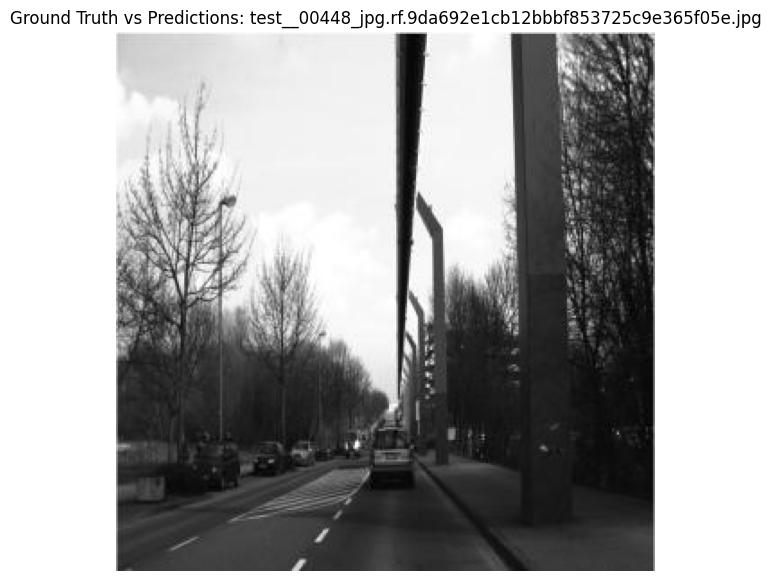

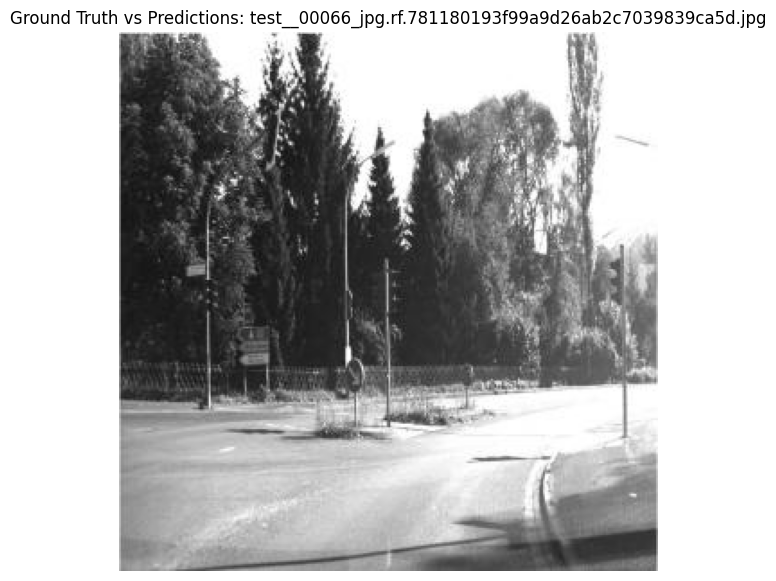

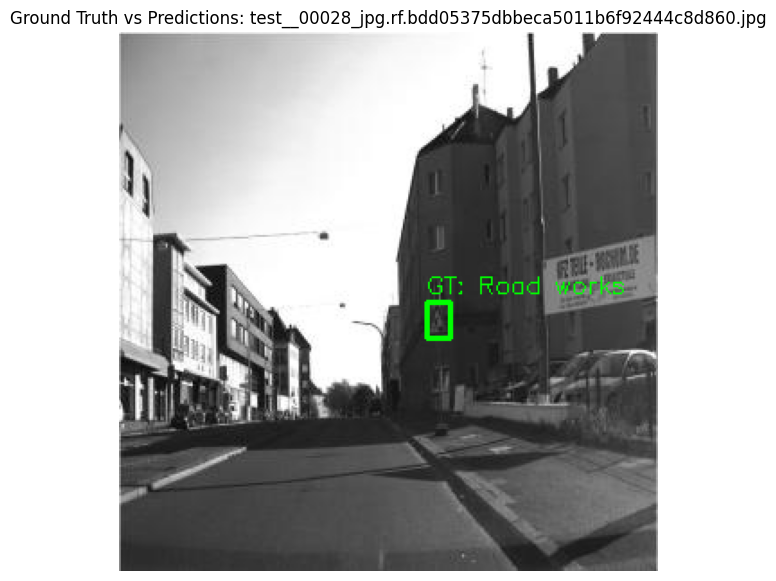

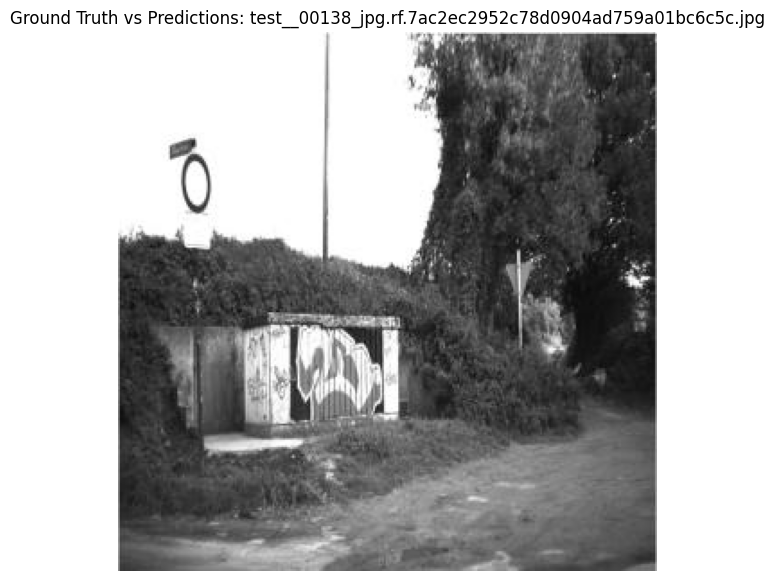

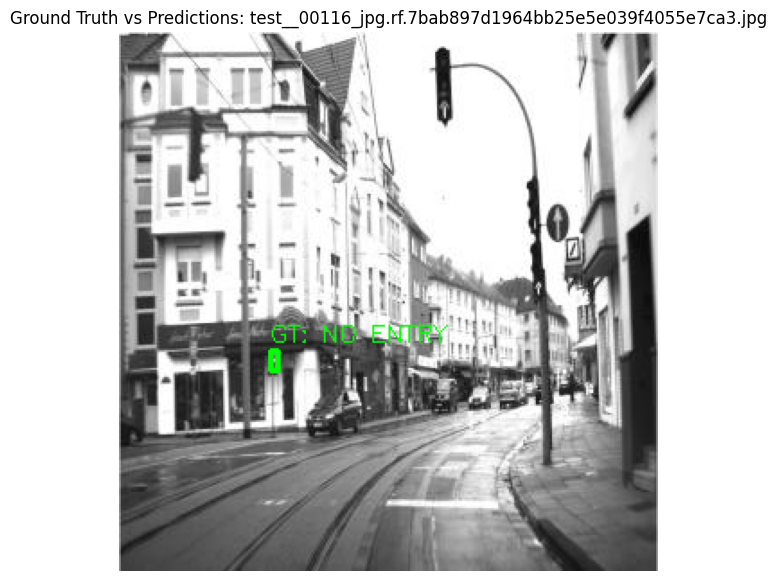

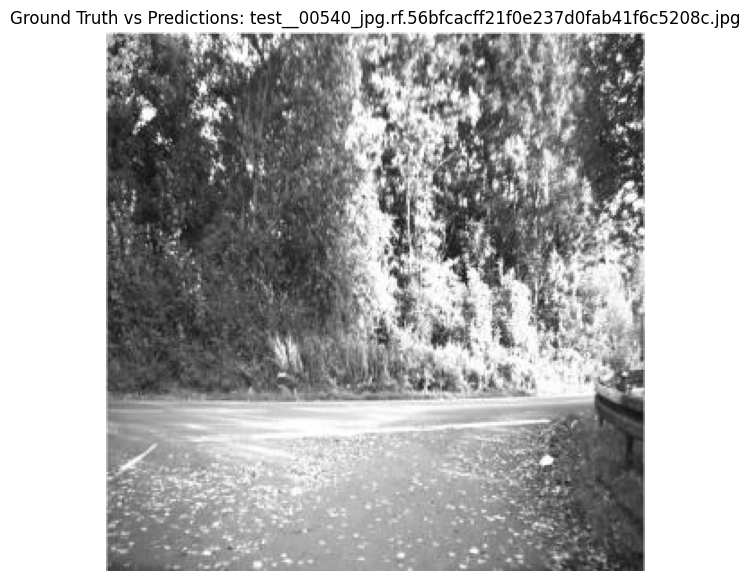

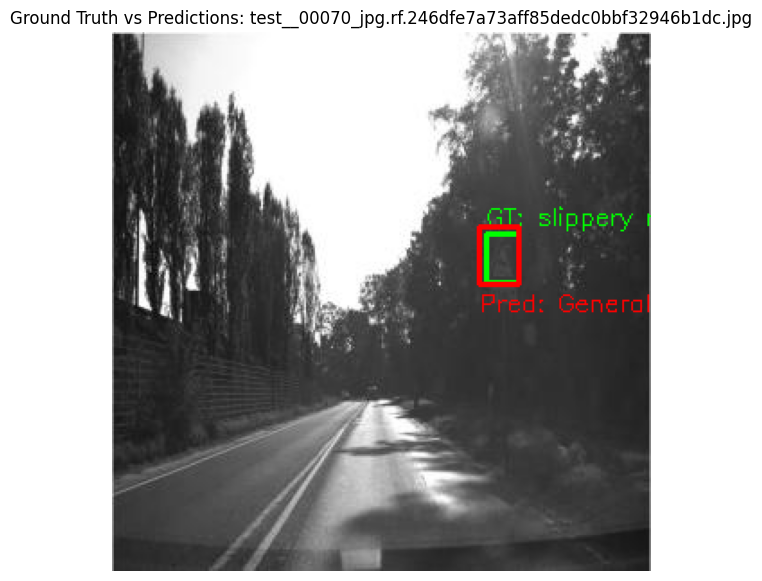

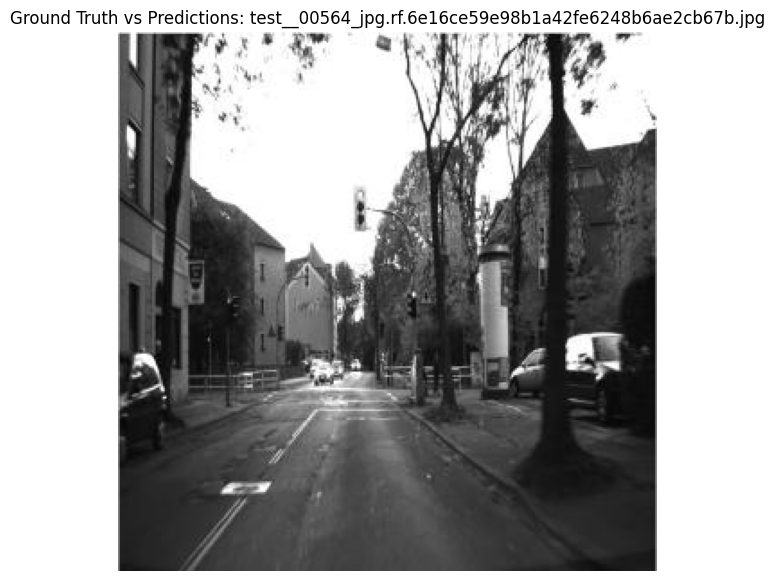

Prediction visualization completed!


In [30]:

# ===== Visualize Predictions vs Ground Truth on Test Images =====

from ultralytics import YOLO
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import yaml
import numpy as np
import random

# --------------------------------------------------
# 1. Load the final trained model
# --------------------------------------------------

MODEL_PATH = Path(
    "/content/traffic_sign_training/final_model/weights/last.pt"
)

TEST_IMAGES_DIR = Path(
    "/content/traffic_sign_final/test/images"
)

TEST_LABELS_DIR = Path(
    "/content/traffic_sign_final/test/labels"
)

TEST_YAML = Path(
    "/content/traffic_sign_final/final_test.yaml"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert TEST_IMAGES_DIR.exists(), "Test images directory not found!"

model = YOLO(str(MODEL_PATH))

# Load class names from the test YAML
with open(TEST_YAML, "r") as f:
    test_config = yaml.safe_load(f)

class_names = test_config["names"]

# --------------------------------------------------
# 2. Select test images
# --------------------------------------------------

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

test_images = sorted([
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.suffix.lower() in image_extensions
])

# Select up to 8 images for visualization
random.seed(42)
selected_images = random.sample(
    test_images,
    min(8, len(test_images))
)

print("Total test images:", len(test_images))
print("Images selected for visualization:", len(selected_images))

# --------------------------------------------------
# 3. Run model predictions
# --------------------------------------------------

predictions = model.predict(
    source=[str(p) for p in selected_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    verbose=False
)

# --------------------------------------------------
# 4. Draw Ground Truth and Predictions
# --------------------------------------------------

for image_path, result in zip(selected_images, predictions):

    # Original image (OpenCV uses BGR)
    image = result.orig_img.copy()

    height, width = image.shape[:2]

    # ----------------------------------------------
    # Draw Ground Truth boxes in GREEN
    # ----------------------------------------------

    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            if not line.strip():
                continue

            class_id, x_center, y_center, box_w, box_h = map(
                float, line.split()
            )

            # Convert normalized YOLO coordinates to pixels
            x_center *= width
            y_center *= height
            box_w *= width
            box_h *= height

            x1 = int(x_center - box_w / 2)
            y1 = int(y_center - box_h / 2)
            x2 = int(x_center + box_w / 2)
            y2 = int(y_center + box_h / 2)

            class_id = int(class_id)
            class_name = class_names[class_id]

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                image,
                f"GT: {class_name}",
                (x1, max(15, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (0, 255, 0),
                1
            )

    # ----------------------------------------------
    # Draw Model Predictions in RED
    # ----------------------------------------------

    if result.boxes is not None:

        for box in result.boxes:

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].cpu().numpy()
            )

            class_id = int(box.cls[0].item())
            confidence = float(box.conf[0].item())

            class_name = class_names[class_id]

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 0, 255),
                2
            )

            cv2.putText(
                image,
                f"Pred: {class_name} ({confidence:.2f})",
                (x1, min(height - 5, y2 + 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (0, 0, 255),
                1
            )

    # Convert BGR to RGB for Matplotlib
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # ----------------------------------------------
    # Display image
    # ----------------------------------------------

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(f"Ground Truth vs Predictions: {image_path.name}")
    plt.axis("off")
    plt.show()

print("Prediction visualization completed!")


Generating Confusion Matrix on the Test set...
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,939 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 538.6±63.4 MB/s, size: 17.2 KB)
val: Scanning /content/traffic_sign_final/test/labels.cache... 26 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 6.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6it/s 1.2s
                   all         26         13      0.391      0.342      0.304      0.206
     Bicycles crossing          1          1      0.337      0.675      0.497      0.149
     Curve to the left          1          1          0          0          0          0
       General caution          1          1          0          0          0          0
              NO ENTRY          1          1          1          0          0       

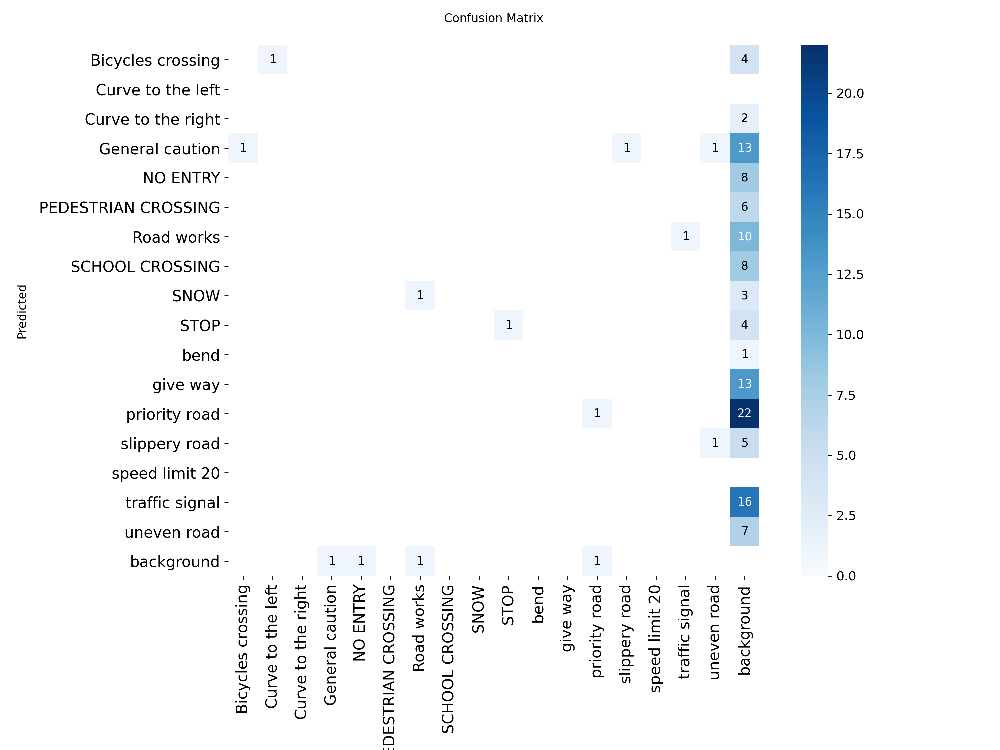


Displaying: confusion_matrix_normalized.png


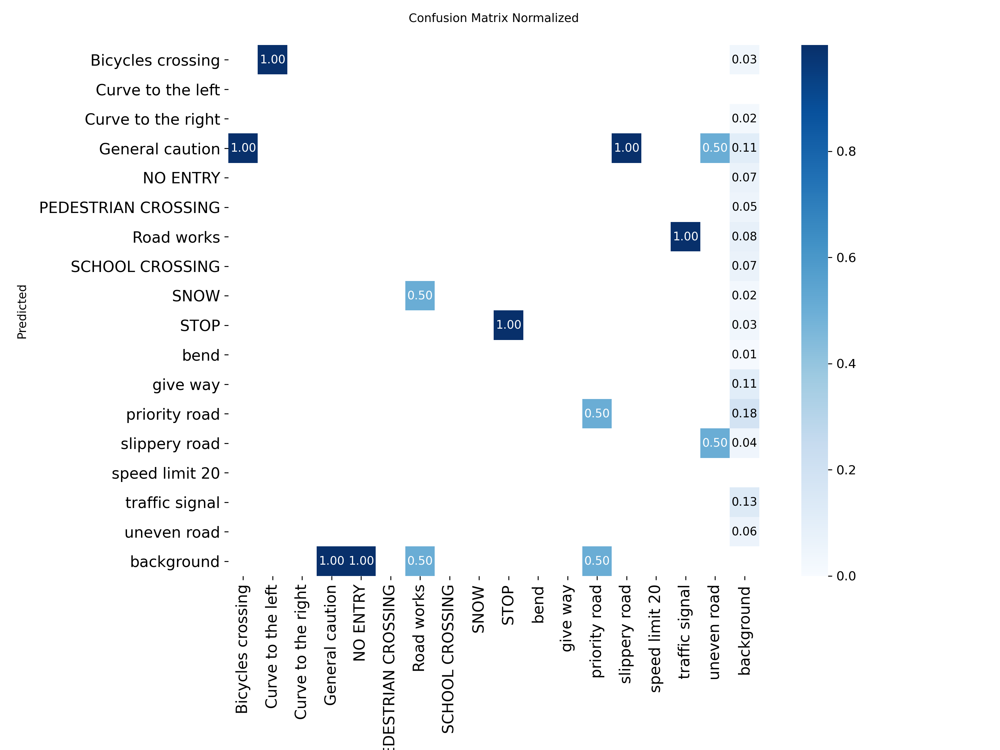


Confusion Matrix analysis completed!
Output directory: /content/traffic_sign_final/evaluation/confusion_matrix_analysis


In [31]:

# ===== Generate and Display Test Confusion Matrix =====

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Image
import yaml

# --------------------------------------------------
# 1. Load the final model
# --------------------------------------------------

MODEL_PATH = Path(
    "/content/traffic_sign_training/final_model/weights/last.pt"
)

TEST_YAML = (
    "/content/traffic_sign_final/final_test.yaml"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

model = YOLO(str(MODEL_PATH))

# --------------------------------------------------
# 2. Evaluate on the independent Test set
# --------------------------------------------------

print("Generating Confusion Matrix on the Test set...")

results = model.val(
    data=TEST_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    verbose=True,
    project="/content/traffic_sign_final/evaluation",
    name="confusion_matrix_analysis",
    exist_ok=True
)

# --------------------------------------------------
# 3. Display evaluation metrics
# --------------------------------------------------

print("\n========== TEST METRICS ==========")

metrics = {
    "Precision": results.box.mp,
    "Recall": results.box.mr,
    "mAP50": results.box.map50,
    "mAP50-95": results.box.map
}

for name, value in metrics.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

# --------------------------------------------------
# 4. Locate and display Confusion Matrix images
# --------------------------------------------------

output_dir = Path(
    "/content/traffic_sign_final/evaluation/"
    "confusion_matrix_analysis"
)

confusion_files = [
    output_dir / "confusion_matrix.png",
    output_dir / "confusion_matrix_normalized.png"
]

for file_path in confusion_files:

    if file_path.exists():

        print(f"\nDisplaying: {file_path.name}")

        display(Image(filename=str(file_path)))

    else:
        print(f"File not found: {file_path.name}")

print("\nConfusion Matrix analysis completed!")
print("Output directory:", output_dir)
